# 5. Input drift

In production the monitor DAG compares the inputs of the last 7 days of predictions with the model's training inputs, feature by feature, using the Population Stability Index (PSI): below 0.1 is stable, 0.1–0.25 a moderate shift, 0.25 or more counts as drift and fires the `InputDrift` alert. This notebook shows what the check sees, with the same code (`aeroscrape.monitoring.drift`), on the archive: first a natural week-to-week change, then two simulated failures.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

import nbutils
from nbutils import BLUE, GREEN, GREY, ORANGE, RED

nbutils.setup()

In [2]:
from aeroscrape.features.preprocess import make_model_frame, prepare_input, variant_feature_set
from aeroscrape.monitoring.drift import detect_drift

config = nbutils.project_config()
flights, _ = nbutils.load_flights()
frame = make_model_frame(flights, config)
features = variant_feature_set(config, "booking")
inputs = prepare_input(frame, features).assign(scheduled=frame["scheduled_datetime"].to_numpy())
cut = inputs["scheduled"].max() - pd.Timedelta(days=7)
reference, current = inputs[inputs["scheduled"] < cut].drop(columns="scheduled"), inputs[inputs["scheduled"] >= cut].drop(columns="scheduled")
CHECKED = config["monitoring"]["drift"]["features"]
NUMERICAL = set(features.numerical)
THRESHOLD = config["monitoring"]["drift"]["psi_threshold"]
print(f"reference: {len(reference):,} departures before {cut:%Y-%m-%d}; current: {len(current):,} in the last week")

Ignoring 3 implausible delays outside [-60, 720] min


reference: 2,398 departures before 2025-06-05; current: 1,176 in the last week


,Last week vs. the weeks before,Simulated: every flight moved to 00:00-04:59,Simulated: registrations stop being published
Scheduled_Hour_of_Day,0.007,7.464,0.007
airline,0.011,0.011,0.011
airline_delay_rate_7d,0.940,0.940,0.940
has_inbound,0.122,0.122,1.799
scheduled_turnaround_min,0.135,0.135,1.305


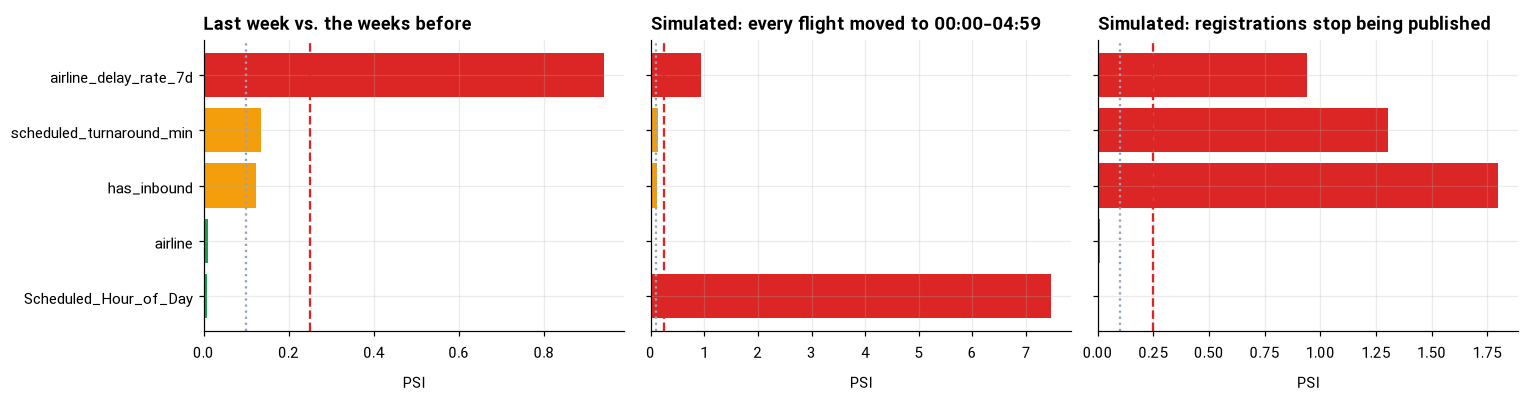

In [3]:
def psi_table(current_inputs):
    results = detect_drift(reference, current_inputs, CHECKED, NUMERICAL, THRESHOLD)
    return pd.Series({r.feature: r.psi for r in results}).sort_values()


def plot_psi(ax, psi, title):
    colors = [RED if v >= THRESHOLD else ORANGE if v >= 0.1 else GREEN for v in psi]
    ax.barh(psi.index, psi.values, color=colors)
    ax.axvline(0.1, color=GREY, ls=":")
    ax.axvline(THRESHOLD, color=RED, ls="--")
    ax.set_title(title)
    ax.set_xlabel("PSI")


scenarios = {
    "Last week vs. the weeks before": current,
    "Simulated: every flight moved to 00:00-04:59": current.assign(Scheduled_Hour_of_Day=lambda d: (d["Scheduled_Hour_of_Day"] % 5).astype(float)),
    "Simulated: registrations stop being published": current.assign(has_inbound=0.0, scheduled_turnaround_min=np.nan),
}
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
table = {}
for ax, (title, data) in zip(axes, scenarios.items()):
    psi = psi_table(data)
    table[title] = psi
    plot_psi(ax, psi, title)
plt.tight_layout()
pd.DataFrame(table).round(3)

- **Natural change**: airline mix and departure hours are stable from week to week (PSI 0.01), and the rotation features move moderately. `airline_delay_rate_7d` is flagged, but for a reason worth knowing: in the archive's first days there is no 7-day history yet, so the rate is missing in much of the reference and present in the last week. A reference must come from a period where every feature can be computed; production compares with the model's whole training window, and a missing-value bin of its own makes this kind of change visible instead of hiding it.
- **Night shift**: the hour of departure explodes far past the threshold, the case the replay demo uses (`make replay NIGHT=1`).
- **Lost registrations**: the rotation features drift without any change in the flights themselves, the failure that actually happened by November 2026, when 84% of scraped flights had no registration.

## What one feature's drift looks like

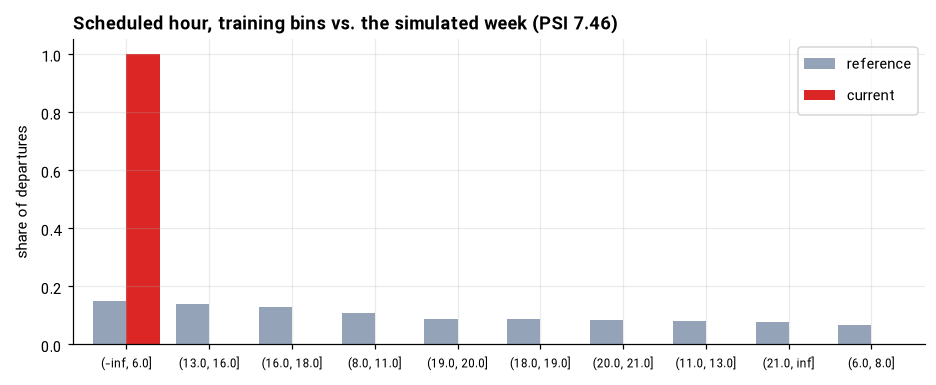

In [4]:
from aeroscrape.monitoring.drift import feature_drift

night = scenarios["Simulated: every flight moved to 00:00-04:59"]
result = feature_drift(reference["Scheduled_Hour_of_Day"], night["Scheduled_Hour_of_Day"], numerical=True, threshold=THRESHOLD)
shares = result.shares.set_index("bin")
ax = shares.plot.bar(color=[GREY, RED], figsize=(10, 3.6), width=0.8)
ax.set_title(f"Scheduled hour, training bins vs. the simulated week (PSI {result.psi:.2f})")
ax.set_ylabel("share of departures")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=0, labelsize=8)

## Takeaways

- PSI per feature separates week-to-week noise from a real change and points at the feature that moved.
- Drift is about inputs, not accuracy: the monitor DAG also matches predictions with actual delays and tracks live MAE, Brier score and coverage against the offline numbers, and only a sustained problem triggers retraining, which the promotion gate still has to approve.